In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

import matplotlib.pyplot as plt
import numpy as np
import time

from torch.utils.data import DataLoader

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [ ]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.5, 0.5, 0.5),
        (0.5, 0.5, 0.5)
    )
])

train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=2
)

classes = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Classes:", classes)

100%|██████████| 170M/170M [37:31<00:00, 75.7kB/s]


Training images: 50000
Testing images: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


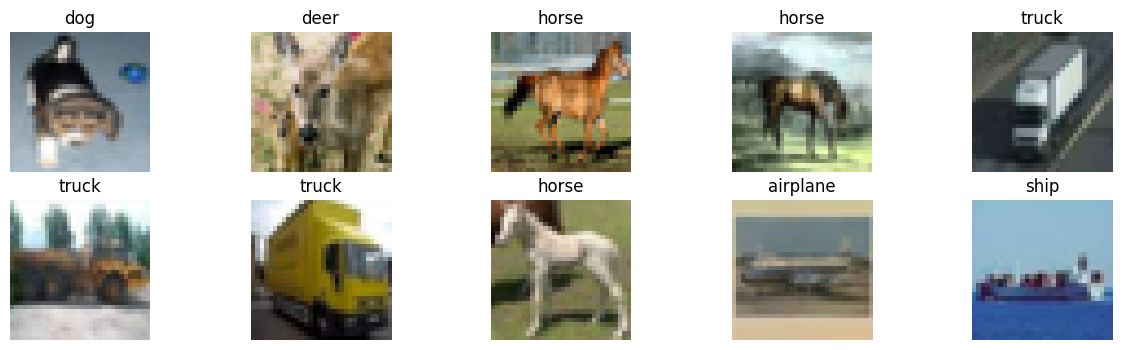

In [ ]:
images, labels = next(iter(train_loader))

images = images[:10]
labels = labels[:10]

plt.figure(figsize=(15, 4))

for i in range(10):
    image = images[i] / 2 + 0.5
    image = image.permute(1, 2, 0)

    plt.subplot(2, 5, i + 1)
    plt.imshow(image)
    plt.title(classes[labels[i]])
    plt.axis("off")

plt.show()

In [ ]:
class TeacherCNN(nn.Module):

    def __init__(self):
        super(TeacherCNN, self).__init__()

        self.features = nn.Sequential(

            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 4 * 4, 512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


teacher = TeacherCNN().to(device)

print(teacher)

TeacherCNN(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (9): ReLU()
    (10): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (12): ReLU()
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (14): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padd

In [ ]:
def count_parameters(model):

    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )


print(
    "Teacher parameters:",
    count_parameters(teacher)
)

Teacher parameters: 3249994


In [ ]:
def train_model(model, train_loader, epochs=10, learning_rate=0.001):

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    train_losses = []
    train_accuracies = []

    for epoch in range(epochs):

        model.train()

        running_loss = 0
        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()

        epoch_loss = running_loss / len(train_loader)

        epoch_accuracy = (
            100 * correct / total
        )

        train_losses.append(epoch_loss)
        train_accuracies.append(epoch_accuracy)

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Loss: {epoch_loss:.4f} "
            f"Accuracy: {epoch_accuracy:.2f}%"
        )

    return train_losses, train_accuracies

In [ ]:
def evaluate_model(model, test_loader):

    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()

    accuracy = 100 * correct / total

    return accuracy

In [ ]:
teacher_losses, teacher_accuracies = train_model(
    teacher,
    train_loader,
    epochs=10,
    learning_rate=0.001
)

Epoch [1/10] Loss: 1.4759 Accuracy: 46.30%
Epoch [2/10] Loss: 0.9816 Accuracy: 65.30%
Epoch [3/10] Loss: 0.7891 Accuracy: 72.65%
Epoch [4/10] Loss: 0.6640 Accuracy: 77.55%
Epoch [5/10] Loss: 0.5688 Accuracy: 80.98%
Epoch [6/10] Loss: 0.4964 Accuracy: 83.25%
Epoch [7/10] Loss: 0.4227 Accuracy: 85.74%
Epoch [8/10] Loss: 0.3623 Accuracy: 87.70%
Epoch [9/10] Loss: 0.3045 Accuracy: 89.67%
Epoch [10/10] Loss: 0.2696 Accuracy: 90.93%


In [ ]:
teacher_accuracy = evaluate_model(
    teacher,
    test_loader
)

print(
    f"Teacher Test Accuracy: "
    f"{teacher_accuracy:.2f}%"
)

Teacher Test Accuracy: 83.79%


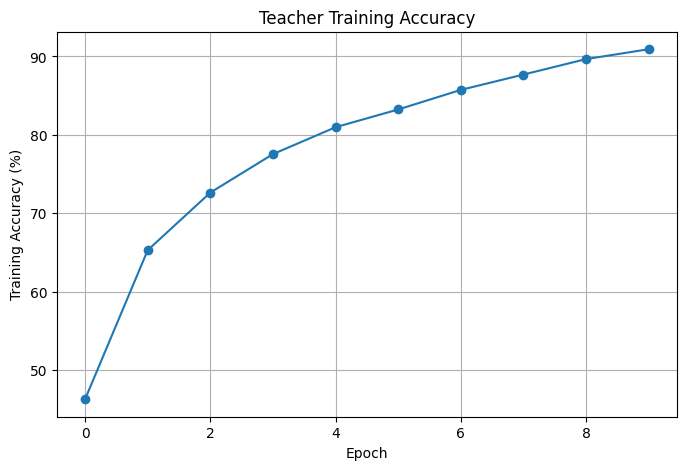

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    teacher_accuracies,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training Accuracy (%)")
plt.title("Teacher Training Accuracy")

plt.grid()

plt.show()

In [ ]:
class StudentCNN(nn.Module):

    def __init__(self):
        super(StudentCNN, self).__init__()

        self.features = nn.Sequential(

            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):

        x = self.features(x)

        x = self.classifier(x)

        return x


student = StudentCNN().to(device)

print(student)

print(
    "Student parameters:",
    count_parameters(student)
)

StudentCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Student parameters: 356810


In [ ]:
student_losses, student_accuracies = train_model(
    student,
    train_loader,
    epochs=10,
    learning_rate=0.001
)

Epoch [1/10] Loss: 1.4987 Accuracy: 45.60%
Epoch [2/10] Loss: 1.0740 Accuracy: 62.03%
Epoch [3/10] Loss: 0.8782 Accuracy: 69.22%
Epoch [4/10] Loss: 0.7563 Accuracy: 73.54%
Epoch [5/10] Loss: 0.6639 Accuracy: 76.96%
Epoch [6/10] Loss: 0.5887 Accuracy: 79.45%
Epoch [7/10] Loss: 0.5118 Accuracy: 82.12%
Epoch [8/10] Loss: 0.4486 Accuracy: 84.31%
Epoch [9/10] Loss: 0.3780 Accuracy: 86.64%
Epoch [10/10] Loss: 0.3255 Accuracy: 88.62%


In [ ]:
student_accuracy = evaluate_model(
    student,
    test_loader
)

print(
    f"Normal Student Test Accuracy: "
    f"{student_accuracy:.2f}%"
)

Normal Student Test Accuracy: 75.28%


In [ ]:
def distillation_loss(
    student_outputs,
    teacher_outputs,
    labels,
    temperature=4.0,
    alpha=0.5
):

    # Normal classification loss
    hard_loss = nn.CrossEntropyLoss()(
        student_outputs,
        labels
    )

    # Soft probabilities from teacher
    teacher_soft = torch.softmax(
        teacher_outputs / temperature,
        dim=1
    )

    # Student soft probabilities
    student_log_soft = torch.log_softmax(
        student_outputs / temperature,
        dim=1
    )

    # Knowledge distillation loss
    soft_loss = nn.KLDivLoss(
        reduction="batchmean"
    )(
        student_log_soft,
        teacher_soft
    )

    # Temperature scaling
    soft_loss = soft_loss * (
        temperature ** 2
    )

    # Final loss
    loss = (
        alpha * hard_loss
        +
        (1 - alpha) * soft_loss
    )

    return loss

In [ ]:
def train_distilled_student(
    student,
    teacher,
    train_loader,
    epochs=10,
    learning_rate=0.001,
    temperature=4.0,
    alpha=0.5
):

    optimizer = optim.Adam(
        student.parameters(),
        lr=learning_rate
    )

    losses = []
    accuracies = []

    teacher.eval()

    for epoch in range(epochs):

        student.train()

        running_loss = 0
        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            # Teacher prediction
            with torch.no_grad():
                teacher_outputs = teacher(images)

            # Student prediction
            student_outputs = student(images)

            # Distillation loss
            loss = distillation_loss(
                student_outputs,
                teacher_outputs,
                labels,
                temperature,
                alpha
            )

            loss.backward()

            optimizer.step()

            running_loss += loss.item()

            _, predicted = torch.max(
                student_outputs,
                1
            )

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()

        epoch_loss = (
            running_loss /
            len(train_loader)
        )

        epoch_accuracy = (
            100 * correct / total
        )

        losses.append(epoch_loss)
        accuracies.append(epoch_accuracy)

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Loss: {epoch_loss:.4f} "
            f"Accuracy: {epoch_accuracy:.2f}%"
        )

    return losses, accuracies

In [ ]:
distilled_student = StudentCNN().to(device)

print(
    "Distilled Student parameters:",
    count_parameters(distilled_student)
)

Distilled Student parameters: 356810


In [ ]:
distill_losses, distill_accuracies = train_distilled_student(
    distilled_student,
    teacher,
    train_loader,
    epochs=10,
    learning_rate=0.001,
    temperature=4.0,
    alpha=0.5
)

Epoch [1/10] Loss: 5.6109 Accuracy: 43.69%
Epoch [2/10] Loss: 3.7659 Accuracy: 58.32%
Epoch [3/10] Loss: 2.9366 Accuracy: 65.09%
Epoch [4/10] Loss: 2.4319 Accuracy: 69.22%
Epoch [5/10] Loss: 2.0963 Accuracy: 72.47%
Epoch [6/10] Loss: 1.8029 Accuracy: 74.89%
Epoch [7/10] Loss: 1.5946 Accuracy: 77.13%
Epoch [8/10] Loss: 1.4199 Accuracy: 78.81%
Epoch [9/10] Loss: 1.2824 Accuracy: 80.24%
Epoch [10/10] Loss: 1.1537 Accuracy: 81.77%


In [ ]:
distilled_accuracy = evaluate_model(
    distilled_student,
    test_loader
)

print(
    f"Distilled Student Test Accuracy: "
    f"{distilled_accuracy:.2f}%"
)

Distilled Student Test Accuracy: 76.49%


In [ ]:
teacher_params = count_parameters(teacher)
student_params = count_parameters(student)
distilled_params = count_parameters(distilled_student)

print("\n==============================")
print("       MODEL COMPARISON")
print("==============================")

print(
    f"Teacher          : "
    f"{teacher_accuracy:.2f}% accuracy | "
    f"{teacher_params:,} parameters"
)

print(
    f"Normal Student   : "
    f"{student_accuracy:.2f}% accuracy | "
    f"{student_params:,} parameters"
)

print(
    f"Distilled Student: "
    f"{distilled_accuracy:.2f}% accuracy | "
    f"{distilled_params:,} parameters"
)


       MODEL COMPARISON
Teacher          : 83.79% accuracy | 3,249,994 parameters
Normal Student   : 75.28% accuracy | 356,810 parameters
Distilled Student: 76.49% accuracy | 356,810 parameters


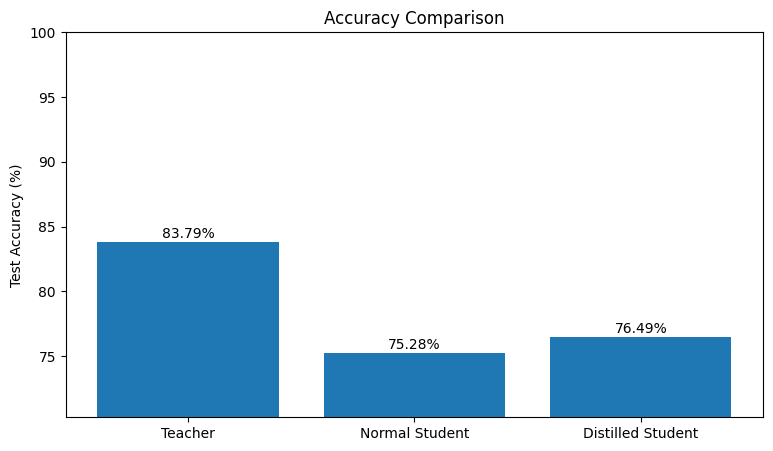

In [ ]:
model_names = [
    "Teacher",
    "Normal Student",
    "Distilled Student"
]

accuracies = [
    teacher_accuracy,
    student_accuracy,
    distilled_accuracy
]

plt.figure(figsize=(9, 5))

bars = plt.bar(
    model_names,
    accuracies
)

plt.ylabel("Test Accuracy (%)")
plt.title("Accuracy Comparison")

plt.ylim(
    min(accuracies) - 5,
    100
)

for bar, accuracy in zip(
    bars,
    accuracies
):

    plt.text(
        bar.get_x() +
        bar.get_width() / 2,
        bar.get_height() + 0.3,
        f"{accuracy:.2f}%",
        ha="center"
    )

plt.show()

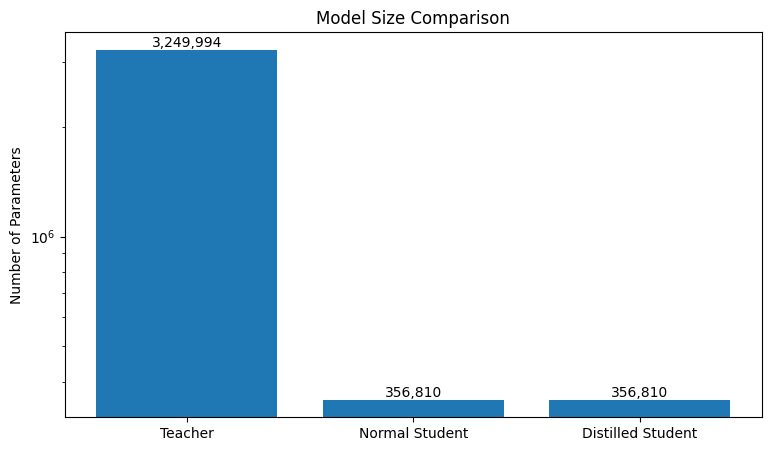

In [ ]:
parameter_counts = [
    teacher_params,
    student_params,
    distilled_params
]

plt.figure(figsize=(9, 5))

bars = plt.bar(
    model_names,
    parameter_counts
)

plt.ylabel("Number of Parameters")
plt.title("Model Size Comparison")

plt.yscale("log")

for bar, count in zip(
    bars,
    parameter_counts
):

    plt.text(
        bar.get_x() +
        bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}",
        ha="center",
        va="bottom"
    )

plt.show()

In [ ]:
compression_ratio = (
    teacher_params /
    student_params
)

print(
    f"Teacher → Student compression ratio: "
    f"{compression_ratio:.2f}x"
)

print(
    f"Teacher parameters: "
    f"{teacher_params:,}"
)

print(
    f"Student parameters: "
    f"{student_params:,}"
)

Teacher → Student compression ratio: 9.11x
Teacher parameters: 3,249,994
Student parameters: 356,810


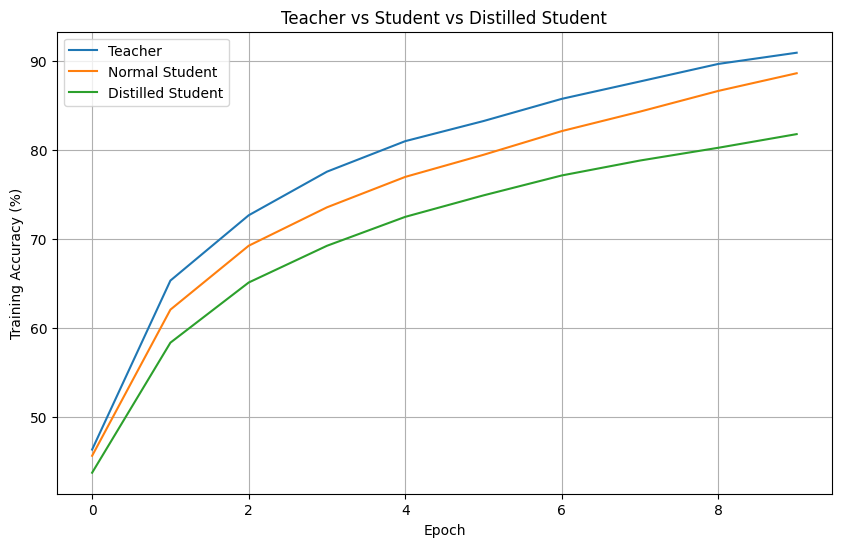

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    teacher_accuracies,
    label="Teacher"
)

plt.plot(
    student_accuracies,
    label="Normal Student"
)

plt.plot(
    distill_accuracies,
    label="Distilled Student"
)

plt.xlabel("Epoch")
plt.ylabel("Training Accuracy (%)")

plt.title(
    "Teacher vs Student vs Distilled Student"
)

plt.legend()

plt.grid()

plt.show()

In [ ]:
def show_prediction(
    model,
    image,
    true_label,
    model_name
):

    model.eval()

    with torch.no_grad():

        output = model(
            image.unsqueeze(0).to(device)
        )

        probabilities = torch.softmax(
            output,
            dim=1
        )

        confidence, predicted = torch.max(
            probabilities,
            1
        )

    image_display = image / 2 + 0.5

    image_display = image_display.permute(
        1, 2, 0
    )

    plt.figure(figsize=(4, 4))

    plt.imshow(image_display)

    plt.title(
        f"{model_name}\n"
        f"Prediction: {classes[predicted.item()]}\n"
        f"Confidence: {confidence.item()*100:.2f}%\n"
        f"Actual: {classes[true_label]}"
    )

    plt.axis("off")

    plt.show()

In [ ]:
image, label = test_dataset[10]

print(
    "Actual class:",
    classes[label]
)

Actual class: airplane


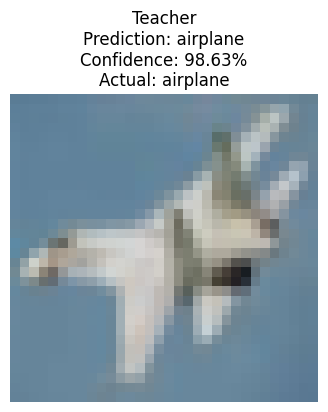

In [ ]:
show_prediction(
    teacher,
    image,
    label,
    "Teacher"
)

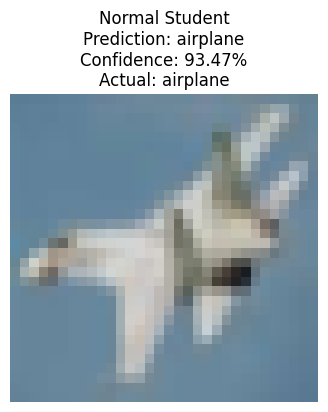

In [ ]:
show_prediction(
    student,
    image,
    label,
    "Normal Student"
)

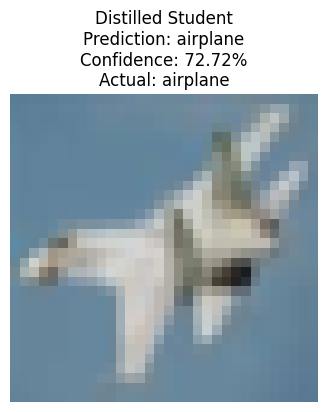

In [ ]:
show_prediction(
    distilled_student,
    image,
    label,
    "Distilled Student"
)

In [ ]:
def get_probabilities(model, image):

    model.eval()

    with torch.no_grad():

        output = model(
            image.unsqueeze(0).to(device)
        )

        probabilities = torch.softmax(
            output,
            dim=1
        )

    return probabilities.cpu().numpy()[0]


teacher_probs = get_probabilities(
    teacher,
    image
)

student_probs = get_probabilities(
    student,
    image
)

distilled_probs = get_probabilities(
    distilled_student,
    image
)

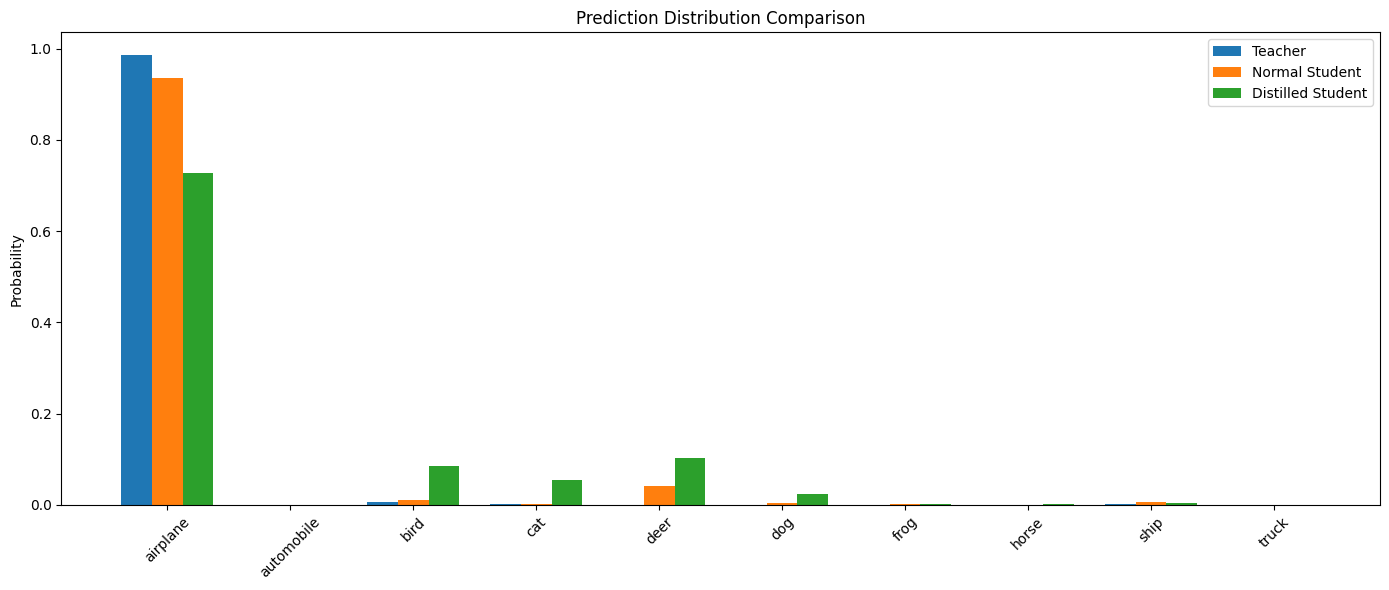

In [ ]:
x = np.arange(len(classes))

width = 0.25

plt.figure(figsize=(14, 6))

plt.bar(
    x - width,
    teacher_probs,
    width,
    label="Teacher"
)

plt.bar(
    x,
    student_probs,
    width,
    label="Normal Student"
)

plt.bar(
    x + width,
    distilled_probs,
    width,
    label="Distilled Student"
)

plt.xticks(
    x,
    classes,
    rotation=45
)

plt.ylabel("Probability")

plt.title(
    "Prediction Distribution Comparison"
)

plt.legend()

plt.tight_layout()

plt.show()

In [ ]:
def measure_inference_time(
    model,
    test_loader,
    num_batches=20
):

    model.eval()

    start_time = time.time()

    with torch.no_grad():

        for i, (images, labels) in enumerate(
            test_loader
        ):

            if i >= num_batches:
                break

            images = images.to(device)

            model(images)

    end_time = time.time()

    total_time = (
        end_time -
        start_time
    )

    return total_time

In [ ]:
teacher_time = measure_inference_time(
    teacher,
    test_loader
)

student_time = measure_inference_time(
    student,
    test_loader
)

distilled_time = measure_inference_time(
    distilled_student,
    test_loader
)

print(
    f"Teacher inference time: "
    f"{teacher_time:.4f} seconds"
)

print(
    f"Student inference time: "
    f"{student_time:.4f} seconds"
)

print(
    f"Distilled student inference time: "
    f"{distilled_time:.4f} seconds"
)

Teacher inference time: 1.1726 seconds
Student inference time: 1.0582 seconds
Distilled student inference time: 0.7243 seconds


In [ ]:
print("\n")
print("=" * 60)
print("              KNOWLEDGE DISTILLATION")
print("=" * 60)

print(
    f"{'Model':<20}"
    f"{'Accuracy':<15}"
    f"{'Parameters':<20}"
)

print("-" * 60)

print(
    f"{'Teacher':<20}"
    f"{teacher_accuracy:.2f}%{'':<9}"
    f"{teacher_params:,}"
)

print(
    f"{'Normal Student':<20}"
    f"{student_accuracy:.2f}%{'':<9}"
    f"{student_params:,}"
)

print(
    f"{'Distilled Student':<20}"
    f"{distilled_accuracy:.2f}%{'':<9}"
    f"{distilled_params:,}"
)

print("=" * 60)

print(
    f"\nCompression ratio: "
    f"{teacher_params / student_params:.2f}x"
)



              KNOWLEDGE DISTILLATION
Model               Accuracy       Parameters          
------------------------------------------------------------
Teacher             83.79%         3,249,994
Normal Student      75.28%         356,810
Distilled Student   76.49%         356,810

Compression ratio: 9.11x
